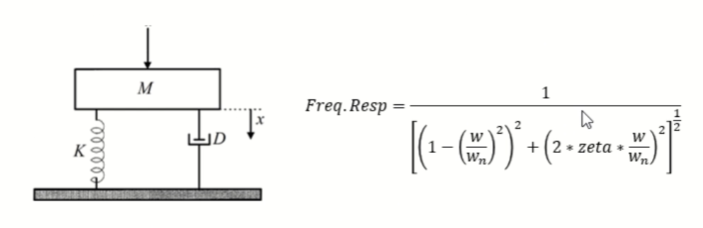

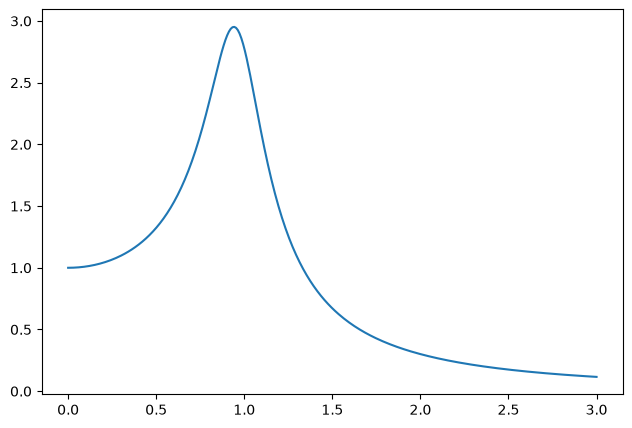

In [3]:
import numpy as np  #given
import matplotlib.pyplot as plt

zeta = 0.3
r = np.linspace(0,3,300)

a = 1-r**2
b = (2*zeta*r)**2
fr = 1/np.sqrt(a**2+b**2)

plt.figure(figsize=(7.5,5))
plt.plot(r,fr)
plt.show()


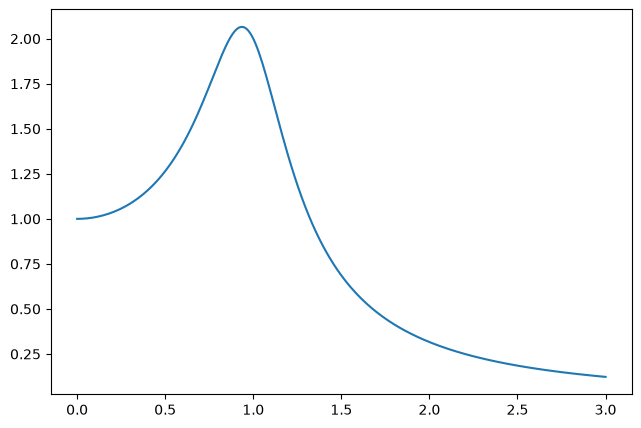

In [4]:
import numpy as np
import matplotlib.pyplot as plt

r = np.linspace(0,3,300) # frequency ration
zeta = 0.25

a = 1-r ** 2
b = 2*zeta*r

fr = 1/np.sqrt(a ** 2+b ** 2)

plt.figure(figsize=(7.5,5))
plt.plot(r,fr)
plt.show()

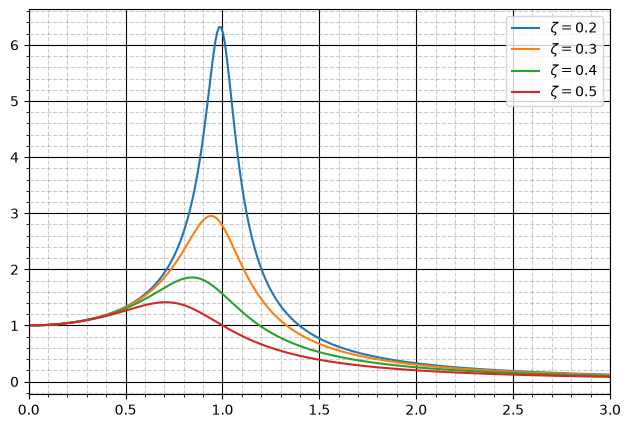

In [5]:
import numpy as np  #given
import matplotlib.pyplot as plt

zeta = [0.2,0.3,0.4,0.5]
r = np.linspace(0,3,300)

plt.figure(figsize=(7.5,5))
for z in zeta:
    a = 1-r**2
    b = (2*z*r)**2
    fr = 1/np.sqrt(a**2+b**2)
    plt.plot(r,fr,label=r'$\zeta={}$'.format(z))

plt.legend(loc='best')
plt.xlim(r[0],r[-1])
plt.grid(which='major',color='black')
plt.minorticks_on()
plt.grid(which='minor',color='grey',alpha=0.4,linestyle='--')
plt.show()

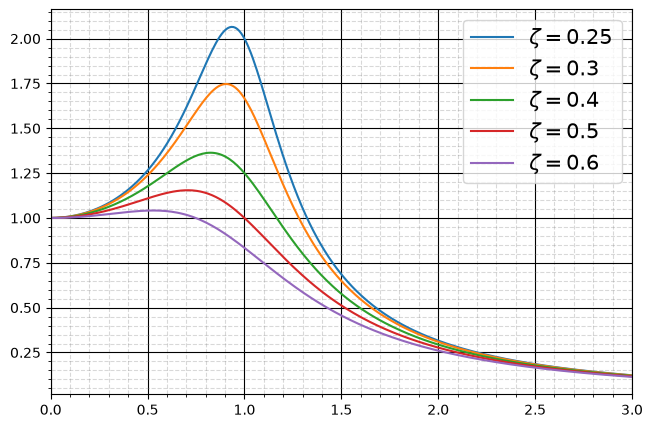

In [6]:
import numpy as np
import matplotlib.pyplot as plt

r = np.linspace(0,3,300) # frequency ration
zeta = [0.25,0.3,0.4,0.5,0.6]

plt.figure(figsize=(7.5,5))

for z in zeta:
    
    a = 1-r ** 2
    b = 2*z*r
    fr = 1/np.sqrt(a ** 2+b ** 2)


    plt.plot(r,fr,label=r'$\zeta={}$'.format(z))

plt.legend(loc='best',fontsize=15)
plt.grid(which='major',color='black')
plt.minorticks_on()
plt.grid(visible=True, which='minor', color='grey', linestyle='--', alpha=0.3)
plt.xlim(r[0],r[-1])
plt.show()


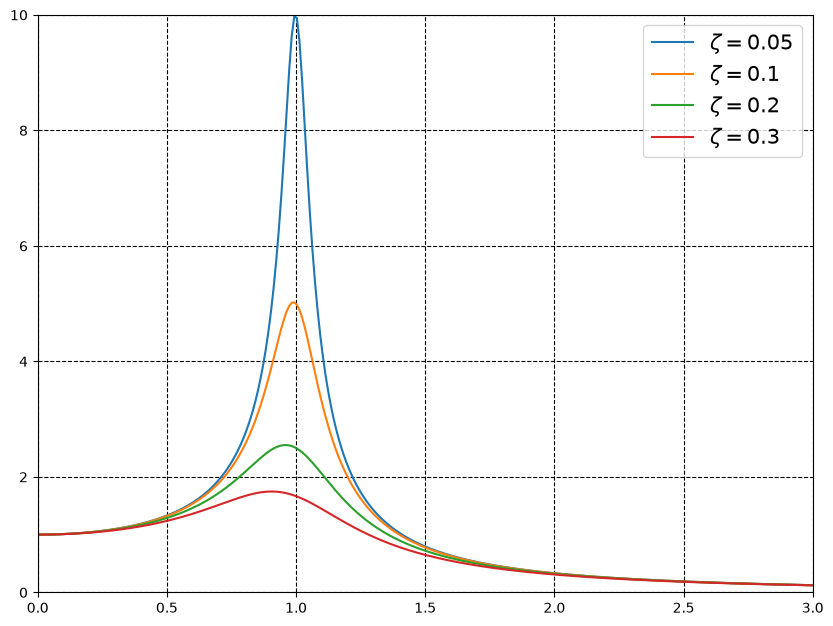

In [1]:
# Frequency Response For SDOF Multiple Plots  #given

import numpy as np
import matplotlib.pyplot as plt
import math

zeta = [0.05,0.1,0.2,0.3]
r = np.linspace(0,3,300)
plt.figure(figsize=(10,7.5))
for z in zeta:
    a = (1-r**2)
    b = (2*z*r)
    f_resp = 1/np.sqrt(a**2+b**2)
    plt.plot(r,f_resp,label=r'$\zeta={}$'.format(z))
    plt.legend(loc = 'upper right',fontsize=15)
    
plt.xlim(r[0],r[-1])
plt.ylim(0,10)
plt.grid(linestyle='--',color = 'k')
plt.show()


In [2]:
# Natural Frequencies of system #given

import numpy as np
from scipy import linalg

m1,m2,m3 = (1,1,1)
k1,k2,k3 = (1600,1600,1600)

M = np.array ([[m1,0,0],
               [0,m2,0],
               [0,0,m3]])

K = np.array ([[k1+k2,-k2,0],
               [-k2,k2+k3,-k3],
               [0,-k3,k3]])

u,v = linalg.eigh(K,M)

nat_freq = np.sqrt(u)

print("First natural frequency :",nat_freq[0])
print("Second natural frequency :",nat_freq[1])
print("Third natural frequency :",nat_freq[2])

First natural frequency : 17.80167471650516
Second natural frequency : 49.879184148698684
Third natural frequency : 72.07750943219354


<>:53: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:53: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
C:\Users\skatikit\AppData\Local\Temp\ipykernel_43696\3991894635.py:53: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
  ax.set_xlabel("Frequency Ratio ($r = \omega / \omega_n$)", fontsize=10)


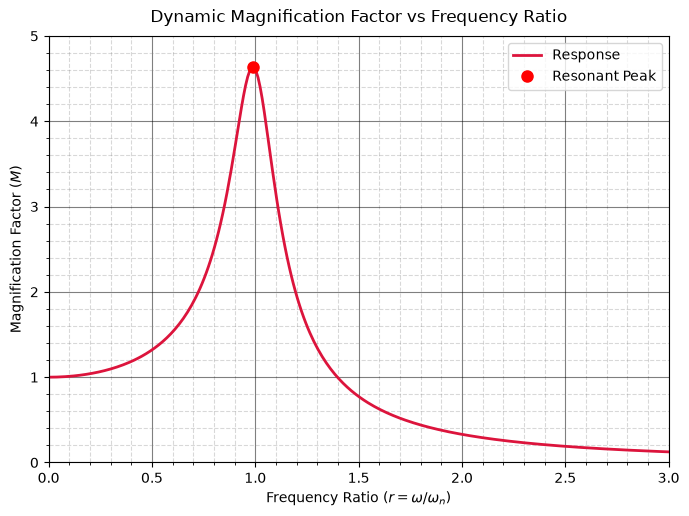

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
import tkinter as tk
from tkinter import ttk

# --- Plotting Function ---
def update_plot(val):
    # Get current damping ratio from slider
    z = float(val)
    zeta_label.config(text=f"Damping Ratio (ζ): {z:.2f}")
    
    # Calculate Frequency Response
    r = np.linspace(0, 3, 300)
    a = 1 - r**2
    b = 2 * z * r
    fr = 1 / np.sqrt(a**2 + b**2)
    
    # Update line data
    line.set_ydata(fr)
    
    # Dynamically update the peak point marker
    if z < 1 / np.sqrt(2):  # Peak exists for r > 0 only if zeta < 0.707
        r_peak = np.sqrt(1 - 2 * z**2)
        fr_peak = 1 / (2 * z * np.sqrt(1 - z**2))
        peak_marker.set_data([r_peak], [fr_peak])
        peak_marker.set_visible(True)
    else:
        peak_marker.set_visible(False)
        
    canvas.draw()

# --- Tkinter GUI Setup ---
root = tk.Tk()
root.title("SDOF Frequency Response Explorer")
root.geometry("800x600")

# Create a frame for the plot
plot_frame = ttk.Frame(root)
plot_frame.pack(side=tk.TOP, fill=tk.BOTH, expand=True)

# Create a frame for controls
control_frame = ttk.Frame(root, padding="10")
control_frame.pack(side=tk.BOTTOM, fill=tk.X)

# --- Initialize Matplotlib Figure ---
fig, ax = plt.subplots(figsize=(7, 4.5))
r_init = np.linspace(0, 3, 300)
z_init = 0.25

# Setup static plot elements
ax.set_title("Dynamic Magnification Factor vs Frequency Ratio", fontsize=12, pad=10)
ax.set_xlabel("Frequency Ratio ($r = \omega / \omega_n$)", fontsize=10)
ax.set_ylabel("Magnification Factor ($M$)", fontsize=10)
ax.grid(which='major', color='black', alpha=0.5)
ax.minorticks_on()
ax.grid(visible=True, which='minor', color='grey', linestyle='--', alpha=0.3)
ax.set_xlim(0, 3)
ax.set_ylim(0, 5)

# Plot initial line and peak marker
line, = ax.plot(r_init, np.zeros_like(r_init), color='crimson', lw=2, label="Response")
peak_marker, = ax.plot([], [], 'ro', markersize=8, label="Resonant Peak")
ax.legend(loc='upper right')

# Embed figure into Tkinter
canvas = FigureCanvasTkAgg(fig, master=plot_frame)
canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)

# --- Control Widgets ---
zeta_label = ttk.Label(control_frame, text="Damping Ratio (ζ): 0.25", font=("Arial", 11))
zeta_label.pack(side=tk.LEFT, padx=10)

# Slider to modify zeta dynamically from 0.05 to 1.00
slider = ttk.Scale(
    control_frame, 
    from_=0.05, 
    to=1.00, 
    orient="horizontal", 
    command=update_plot
)
slider.set(z_init)  # Set initial slider value
slider.pack(side=tk.LEFT, fill=tk.X, expand=True, padx=10)

# Initialize the plot with the default value
update_plot(z_init)

# Run application
root.mainloop()


<>:105: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:105: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
C:\Users\skatikit\AppData\Local\Temp\ipykernel_43696\2553365927.py:105: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
  ax.set_xlabel("Excitation Frequency ($\omega$ in rad/s)", fontsize=10)
Exception in Tkinter callback
Traceback (most recent call last):
  File "c:\Program Files\Python314\Lib\tkinter\__init__.py", line 2093, in __call__
    return self.func(*args)
           ~~~~~~~~~^^^^^^^
  File "C:\Users\skatikit\AppData\Local\Temp\ipykernel_43696\2553365927.py", line 13, in update_plot
    k = float(stiffness_slider.get())  # Current stiffness (k) in N/m
              ~~~~~~~~

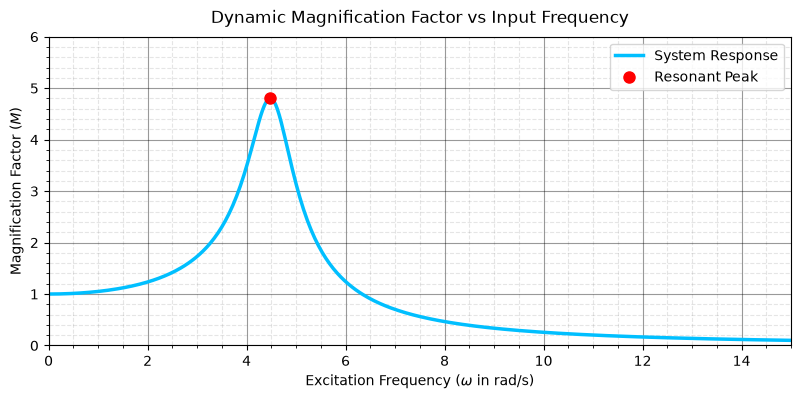

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
import tkinter as tk
from tkinter import ttk

# --- Dynamic Physics Engine & Plotting Function ---
# This function triggers automatically whenever ANY of the three sliders are dragged.
def update_plot(val):
    try:
        # 1. Pull active physical attributes from all three Tkinter sliders
        m = float(mass_slider.get())        # Current mass (m) in kg
        k = float(stiffness_slider.get())  # Current stiffness (k) in N/m
        c = float(damping_slider.get())    # Current damping coefficient (c) in N·s/m
        
        # 2. Compute the dependent structural dynamics properties
        w_n = np.sqrt(k / m)               # Undamped Natural Frequency (ω_n = √[k/m] in rad/s)
        zeta = c / (2 * np.sqrt(k * m))    # Calculated Damping Ratio (ζ = c / c_critical)
        
        # 3. Update the UI text labels with the freshly calculated physics metrics
        mass_label.config(text=f"Mass (m): {m:.1f} kg")
        stiffness_label.config(text=f"Stiffness (k): {k:.1f} N/m")
        damping_label.config(text=f"Damping (c): {c:.2f} N·s/m")
        metrics_label.config(text=f"Calculated Metrics →  ω_n: {w_n:.2f} rad/s  |  ζ: {zeta:.3f}")
        
        # 4. Generate frequency response curve across an absolute frequency sweep (w)
        w = np.linspace(0, 15, 400)
        r = w / w_n
        a = 1 - r**2        # Real/Inertial part of the dynamic response
        b = 2 * zeta * r    # Imaginary/Dissipative part of the dynamic response
        fr = 1 / np.sqrt(a**2 + b**2) # Magnification Factor array
        
        # Push the new coordinates directly into our persistent Matplotlib line object
        line.set_xdata(w)
        line.set_ydata(fr)
        
        # 5. Track and update the Resonant Peak point marker
        if zeta < 1 / np.sqrt(2):
            w_peak = w_n * np.sqrt(1 - 2 * zeta**2)             # Peak frequency location (rad/s)
            fr_peak  = 1 / (2 * zeta * np.sqrt(1 - zeta**2))     # Peak magnification height (M)
            
            # Reposition the red dot marker precisely over the peak
            peak_marker.set_data([w_peak], [fr_peak])
            peak_marker.set_visible(True)
            
            # Dynamically update the formulas pane to show current operational calculations
            formula_text = (
                "--- ACTIVE FORMULAS ---\n\n"
                "Natural Frequency:\n"
                f" ω_n = √(k/m) = √({k:.1f}/{m:.1f}) = {w_n:.2f} rad/s\n\n"
                "Damping Ratio:\n"
                f" ζ = c / (2√(km)) = {c:.2f} / (2√({k:.1f}×{m:.1f})) = {zeta:.3f}\n\n"
                "Resonant Peak:\n"
                f" ω_peak = ω_n√(1 - 2ζ²) = {w_peak:.2f} rad/s\n"
                f" M_max = 1 / (2ζ√(1-ζ²)) = {fr_peak:.2f}"
            )
        else:
            # If the system is heavily damped, no standalone resonant peak point exists
            peak_marker.set_visible(False)
            formula_text = (
                "--- ACTIVE FORMULAS ---\n\n"
                "Natural Frequency:\n"
                f" ω_n = √(k/m) = √({k:.1f}/{m:.1f}) = {w_n:.2f} rad/s\n\n"
                "Damping Ratio:\n"
                f" ζ = c / (2√(km)) = {c:.2f} / (2√({k:.1f}×{m:.1f})) = {zeta:.3f}\n\n"
                "Resonant Peak:\n"
                " No local peak exists because ζ ≥ 0.707 (Heavily Damped)"
            )
            
        # Push the built text string directly into the text box UI component
        formula_box.config(state=tk.NORMAL)   # Temporarily unlock to rewrite contents
        formula_box.delete("1.0", tk.END)     # Flush previous text clear
        formula_box.insert(tk.END, formula_text) # Inject new live math data
        formula_box.config(state=tk.DISABLED) # Lock back down to prevent user editing
        
        # 6. Smoothly redraw the viewport canvas to show updates
        canvas.draw()
        
    except ValueError:
        pass # Safeguard against temporary empty slider strings during rapid UI updates

# --- Tkinter Window & Workspace Grid Layout ---
root = tk.Tk()
root.title("Advanced SDOF Physical Parameter Sandbox")
root.geometry("950x750")

# Primary layout division frames
plot_frame = ttk.Frame(root)
plot_frame.pack(side=tk.TOP, fill=tk.BOTH, expand=True)

# Main control panel area holding both sliders and the formula panel side-by-side
control_frame = ttk.Frame(root, padding="15")
control_frame.pack(side=tk.BOTTOM, fill=tk.X)

# Divide control area into Left (Sliders) and Right (Formula Panel) sub-frames
sliders_subframe = ttk.Frame(control_frame)
sliders_subframe.pack(side=tk.LEFT, fill=tk.BOTH, expand=True)

formula_subframe = ttk.LabelFrame(control_frame, text=" Live Equations & Math Breakdown ", padding="10")
formula_subframe.pack(side=tk.RIGHT, fill=tk.BOTH, padx=(15, 0))

# --- Matplotlib Plot Architecture Initialization ---
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.set_title("Dynamic Magnification Factor vs Input Frequency", fontsize=12, pad=10)
ax.set_xlabel("Excitation Frequency ($\omega$ in rad/s)", fontsize=10)
ax.set_ylabel("Magnification Factor ($M$)", fontsize=10)

# Build out gridlines for data tracking
ax.grid(which='major', color='black', alpha=0.4)
ax.minorticks_on()
ax.grid(visible=True, which='minor', color='grey', linestyle='--', alpha=0.2)

# Lock frame layout boundaries so changing variables doesn't stretch axes
ax.set_xlim(0, 15)
ax.set_ylim(0, 6)

line, = ax.plot([], [], color='deepskyblue', lw=2.5, label="System Response")
peak_marker, = ax.plot([], [], 'ro', markersize=8, label="Resonant Peak")
ax.legend(loc='upper right')

# Mount the figure frame seamlessly into Tkinter's native frame container
canvas = FigureCanvasTkAgg(fig, master=plot_frame)
canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)

# --- Constructing Interactive Multi-Variable Sliders (Left Panel) ---
# --- ROW 1: MASS CONTROLLER ---
mass_label = ttk.Label(sliders_subframe, text="Mass (m): 1.0 kg", width=25, font=("Arial", 10, "bold"))
mass_label.grid(row=0, column=0, sticky="w", pady=5)
mass_slider = ttk.Scale(sliders_subframe, from_=0.5, to=5.0, orient="horizontal", command=update_plot)
mass_slider.set(2.0) 
mass_slider.grid(row=0, column=1, sticky="ew", padx=10, pady=5)

# --- ROW 2: STIFFNESS CONTROLLER ---
stiffness_label = ttk.Label(sliders_subframe, text="Stiffness (k): 100.0 N/m", width=25, font=("Arial", 10, "bold"))
stiffness_label.grid(row=1, column=0, sticky="w", pady=5)
stiffness_slider = ttk.Scale(sliders_subframe, from_=10.0, to=200.0, orient="horizontal", command=update_plot)
stiffness_slider.set(80.0) 
stiffness_slider.grid(row=1, column=1, sticky="ew", padx=10, pady=5)

# --- ROW 3: DAMPING CONTROLLER ---
damping_label = ttk.Label(sliders_subframe, text="Damping (c): 5.00 N·s/m", width=25, font=("Arial", 10, "bold"))
damping_label.grid(row=2, column=0, sticky="w", pady=5)
damping_slider = ttk.Scale(sliders_subframe, from_=0.0, to=25.0, orient="horizontal", command=update_plot)
damping_slider.set(4.5) 
damping_slider.grid(row=2, column=1, sticky="ew", padx=10, pady=5)

sliders_subframe.columnconfigure(1, weight=1)

# Derived System Summary Dashboard Footer (Underneath sliders)
metrics_label = ttk.Label(sliders_subframe, text="", font=("Arial", 11, "italic"), foreground="darkblue")
metrics_label.grid(row=3, column=0, columnspan=2, pady=15)

# --- Constructing Formula Box Panel (Right Panel) ---
# Using a stylized Tkinter Text widget to show multi-line mathematical execution cleanly
formula_box = tk.Text(
    formula_subframe, 
    width=45, 
    height=9, 
    font=("Courier New", 10), 
    bg="#f4f4f6", 
    relief="solid", 
    bd=1,
    padx=5,
    pady=5
)
formula_box.pack(fill=tk.BOTH, expand=True)

# Prime the simulation loop with standard startup configurations at launch
update_plot(None)

# Execute the runtime window loop listener
root.mainloop()
